# Comparative alphabets: information, phylogenetic gain and ancestral sharpness

**Question:** do representations retaining more phylogenetic signal also give
more concentrated ancestral character distributions?

This read-only analysis combines the completed OMA information comparisons,
controlled/native phylogenetic gain, native RAxML ancestral sharpness, and
paired ARPIP/RAxML comparisons. It never launches inference. All seven alphabets
appear in the coverage tables and relevant plots; missing ancestral results
remain N/A rather than being imputed.

Run top-to-bottom in the `foldtree2` environment. Results are local benchmark
artifacts, not bundled datasets. Plots are embedded below when execution finishes.
See [the detailed sharpness notebook](ancestral-sharpness-depth.ipynb).

## Metric guide

Here, $K$ is the alphabet size; a **token** is one alphabet character, and
a **family** is a set of related proteins. Higher is not automatically better:
each metric answers a different question.

### Information in the observed sequences

| Metric | What it measures | How to read it |
| --- | --- | --- |
| Global token entropy / $\log_2 K$ | Diversity of token usage across a family's sequences, normalized by alphabet size. | Near 0 means usage is concentrated in a few states; near 1 means more uniform usage. |
| Effective states | $2^H$, where $H$ is the global token entropy in bits. | The equivalent number of equally frequent states; not simply the number observed. |
| Held-out entropy rate | Bits per token needed to predict held-out proteins using a Markov model trained on other proteins in the same family. | Lower means better held-out prediction for that model order; orders use different lengths of preceding context. |
| Family-held-out MDL proxy | Held-out encoding cost plus an approximate model-complexity penalty, in bits per token. | Lower means shorter total description under this proxy; it is not an exact MDL score. |
| Residue-matched AA mutual information | Statistical association, in bits, between a structural token and the amino acid at the same residue, pooled within a family. | Higher means more shared information with AA, not necessarily more phylogenetic signal. AA versus itself is N/A. |
| Column-equivalent AA mutual information | Association between structural tokens and amino acids across taxa at corresponding AA-alignment columns, averaged within families. | Higher means more shared information at matched columns; this differs from residue-matched MI pooled across positions. |
| Eligible position entropy / $\log_2 K$ | Average sequence-weighted diversity across eligible alignment columns, normalized by alphabet size. | Lower means more conserved columns on average; higher means more variable columns. |
| k=2 discrimination accuracy | Fraction of held-out sequences assigned to the correct family using two-token sets and family prototypes. | Higher means better family discrimination in the 100-family classification subset; bars are fold SEMs. |

### Phylogenetic gain and ancestral distributions

| Metric | What it measures | How to read it |
| --- | --- | --- |
| Phylogenetic gain | Tree log-likelihood minus independent-tip baseline log-likelihood, in nats per eligible column. | Positive values favor the tree model over that baseline. Controlled results use common columns and a fixed topology; native results use each representation's alignment and fitted tree. |
| Gain minus same-run AA | Family-paired gain difference from the AA baseline in the same run. | Positive means greater gain than that baseline; native columns are not paired across representations. |
| Normalized depth | Root-to-node substitution distance divided by the greatest root-to-tip distance in that tree. | Position within that representation's tree, not elapsed time or a shared node identity. |
| Maximum posterior probability | Probability of the most likely ancestral character at a node/site. | Higher means a more concentrated posterior. |
| Normalized posterior entropy | $-\sum_c p(c)\log_2 p(c)/\log_2 K$ for an ancestral node/site. | 0 is concentrated on one character; 1 is uniform. Lower means sharper. |
| Uniform-baseline adjusted sharpness | $(Kp_{\max}-1)/(K-1)$, based on the maximum posterior probability. | 0 corresponds to a uniform posterior and 1 to certainty. |
| Fraction with maximum $\geq 0.90$ | Proportion of eligible node/sites whose most likely character has posterior probability at least 0.90. | Higher means more high-confidence calls, not necessarily more correct calls. |
| Spearman rho | Rank correlation of family-level native gain with family-level normalized ancestral entropy, calculated separately for each representation. | Negative means higher gain tends to accompany lower entropy; association is not causation. |
| ARPIP minus RAxML entropy | Within-family difference in normalized posterior entropy on the same ARPIP-present node/sites. | Negative means ARPIP is sharper; fitted and constant-rate RAxML are separate comparisons. |
| ARPIP absence fraction | Fraction of matched node/sites inferred absent by ARPIP. | A deterministic inferred gap fraction, not a calibrated gap probability. |

Error bars and shading are 95% whole-family bootstrap intervals, except for
the k=2 fold SEMs; the absence-fraction panel is a boxplot. Normalization does
not remove alphabet or model effects. Sharp posteriors and high gain do **not**
establish ancestral or tree accuracy.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/production_models.yaml').exists())
sys.path.insert(0, str(REPO))
from scripts.ancestral.ancestral_inspection import inventory, select_cohort, summarize_depth, bootstrap_curves, REPRESENTATIONS
RESULT_ROOTS = [REPO / 'runs/local_benchmarks/full_native_ancestral_20261001', REPO / 'runs/local_benchmarks/missing_alphabet_analysis_20261001']
COMMON_FAMILIES = True  # Intersection across representations with completed outputs.
MAX_FAMILIES = None     # All valid common families; set an integer for quick inspection.
DEPTH_BINS = 10
BOOTSTRAP_DRAWS = 1000
SEED = 42
MIN_FAMILIES_PER_BIN = 5
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = dict(zip(REPRESENTATIONS, plt.get_cmap('tab10').colors))

from scripts.benchmark_common import digest
from scripts.benchmarks.benchmark_cohort import verify_stage
from scripts.ancestral.ancestral_inspection import METRICS

COHORT_PATH = REPO / 'configs/oma_benchmark_cohort.json'
COHORT_HASH = digest(COHORT_PATH)
GAIN_SOURCES = {
    'core': REPO / 'runs/local_benchmarks/oma_joint_comparison_20261001',
    'ten': REPO / 'runs/local_benchmarks/missing_alphabet_analysis_20261001/joint_comparison',
    'fifty': REPO / 'runs/local_benchmarks/accepted50_20261006/joint_comparison',
}
SOURCE_REPRESENTATIONS = {
    'core': ['AA', '3Di', 'FT2_20', 'FT2_30', 'FT2_40'],
    'ten': ['FT2_10'],
    'fifty': ['FT2_50'],
}
SIZES = {'AA': 20, '3Di': 20, **{f'FT2_{k}': k for k in [10, 20, 30, 40, 50]}}
cohort = json.loads(COHORT_PATH.read_text())
family_ids = {row['family'] for row in cohort['families']}

def interval(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2 or not np.isfinite(values).all():
        raise ValueError('Bootstrap requires at least two finite family values')
    rng = np.random.default_rng(SEED)
    means = values[rng.integers(len(values), size=(BOOTSTRAP_DRAWS, len(values)))].mean(axis=1)
    return values.mean(), *np.quantile(means, [.025, .975])

def point(ax, x, values, color, offset=0, label=None):
    mean, low, high = interval(values)
    ax.errorbar(x + offset, mean, yerr=[[max(0, mean-low)], [max(0, high-mean)]],
                fmt='o', color=color, capsize=3, label=label)

def alphabet_axis(ax, counts=None):
    labels = [r.replace('_', '-') for r in REPRESENTATIONS]
    if counts is not None:
        labels = [f'{label}\n(n={int(counts.get(r, 0))})' for r, label in zip(REPRESENTATIONS, labels)]
    ax.set_xticks(range(len(labels)), labels, fontsize=8)
    ax.set_xlim(-.6, len(labels)-.4)
    ax.grid(axis='y', alpha=.2)

## 1. Provenance and phylogenetic-gain coverage

The frozen cohort has 499 eligible families. Core results supply AA, 3Di and
FT2-20/30/40; separate completed runs supply FT2-10 and FT2-50. Repeated AA/3Di
baselines are not counted twice. Per-family gain artifacts are hash-verified
and their summaries checked against the aggregate tables.

**Controlled gain** uses common FoldMason columns and the OMA AA topology.
Occupancy masks belong to each source run, so FT2-versus-AA differences use
the AA baseline **from the same run**, never a baseline from a different mask.
**Native gain** uses each representation's own alignment and fitted tree;
its columns are not paired across representations. Neither is a concatenated
species-supermatrix benchmark.

FT2-50's matrix was explicitly accepted without EMA convergence; its information
and gain results must retain that caveat. This does not imply FT2-50 ASR exists.

In [2]:
gain_parts, delta_parts, source_rows = [], [], []
native_gain_signatures = {}
protocols = {'controlled': 'FoldMason_common_columns_OMA_AA_topology',
             'native': 'native_tree_native_alignment'}
for source, root in GAIN_SOURCES.items():
    signature = json.loads((root / 'provenance.json').read_text())
    complete = json.loads((root / 'completed.json').read_text())
    if (signature['protocol'] != 'joint_OMA_AA_3Di_FT2_v1'
            or signature['cohort_sha256'] != COHORT_HASH
            or complete['status'] != 'completed' or complete['failures']
            or complete['n_families'] != len(family_ids)
            or any(complete[key] != value for key, value in signature.items())):
        raise ValueError(f'Invalid comparative completion/provenance: {root}')
    retained = SOURCE_REPRESENTATIONS[source]
    source_rows.append({'source': source, 'representations': ', '.join(retained),
                        'families': complete['n_families'], 'directory': str(root.relative_to(REPO))})
    for mode, protocol in protocols.items():
        table = pd.read_csv(root / f'{mode}-gain.csv', dtype={'family': str})
        expected = {(f, r) for f in family_ids for r in signature['models']}
        if (table.duplicated(['family', 'model']).any()
                or set(zip(table.family, table.model)) != expected
                or set(table.protocol) != {protocol}):
            raise ValueError(f'Incomplete/duplicate gain coverage: {source}/{mode}')
        checked = table[table.model.isin(set(retained) | {'AA'})]
        for record in checked.to_dict('records'):
            directory = root / protocol / record['family'] / record['model']
            stage = verify_stage(directory)
            if (stage['family'] != record['family'] or stage['representation'] != record['model']
                    or stage['protocol'] != protocol):
                raise ValueError(f'Gain stage identity mismatch: {directory}')
            summary = json.loads((directory / 'summary.json').read_text())
            for key, value in summary.items():
                actual = record[key]
                equal = (np.isclose(actual, value, rtol=1e-10, atol=1e-10, equal_nan=True)
                         if isinstance(value, (int, float)) else actual == value)
                if not equal:
                    raise ValueError(f'Aggregate differs from verified summary: {directory}/{key}')
            if mode == 'native' and record['model'] in retained:
                native_gain_signatures[(record['family'], record['model'])] = stage
        numeric = ['phylo_gain_mean', 'h_tip_mean', 'loglik_tree_mean', 'loglik_iid_mean']
        if (not np.isfinite(table[numeric].to_numpy()).all() or (table.n_columns <= 0).any()
                or not np.allclose(table.phylo_gain_mean, table.loglik_tree_mean-table.loglik_iid_mean)):
            raise ValueError(f'Invalid gain values: {source}/{mode}')
        selected_gain = table[table.model.isin(retained)].rename(columns={'model': 'representation'}).copy()
        selected_gain['source'], selected_gain['mode'] = source, mode
        gain_parts.append(selected_gain)
        baseline = table[table.model == 'AA'][['family', 'phylo_gain_mean']].rename(
            columns={'phylo_gain_mean': 'aa_gain'})
        delta = selected_gain.merge(baseline, on='family', validate='many_to_one')
        delta['gain_minus_AA'] = delta.phylo_gain_mean - delta.aa_gain
        delta_parts.append(delta)
gain = pd.concat(gain_parts, ignore_index=True)
gain_deltas = pd.concat(delta_parts, ignore_index=True)
if gain.duplicated(['family', 'representation', 'mode']).any():
    raise ValueError('Duplicate selected gain results')
display(pd.DataFrame(source_rows))
display(gain.groupby(['representation', 'mode']).family.nunique().unstack().reindex(REPRESENTATIONS))

,source,representations,families,directory
0,core,"AA, 3Di, FT2_20, FT2_30, FT2_40",499,runs/local_benchmarks/oma_joint_comparison_202...
1,ten,FT2_10,499,runs/local_benchmarks/missing_alphabet_analysi...
2,fifty,FT2_50,499,runs/local_benchmarks/accepted50_20261006/join...


mode,controlled,native
representation,,
AA,499,499
3Di,499,499
FT2_10,499,499
FT2_20,499,499
FT2_30,499,499
FT2_40,499,499
FT2_50,499,499


## 2. Comparative information analysis

Unshuffled results only. Global token entropy and eligible position entropy
are divided by log2(K). Entropy-rate and MDL panels retain bits/token:
they are predictive/compression measures, not scores on a universal alphabet.
MDL is a model-cost **proxy**, shown on a log scale and averaged over recorded held-out folds, not a
family-bootstrap interval. MI is empirical residue-matched mutual information
with AA; AA-versus-AA is omitted (N/A), not assigned zero.

The k=2 discrimination score uses the recorded **100-family classification
subset**, not the 499-family gain/ASR cohort. Error bars there are recorded
fold SEMs. Other family-level bars are 95% family-bootstrap intervals.
Large column tables are reduced to family means before pooling.

Information tables have legacy completion/provenance checks but no recorded
output hashes. Their structure and family coverage are checked here; do not
interpret that as cryptographic validation of those CSVs.

,families,entropy_bits,effective_states
representation,,,
AA,499,4.1179,17.3802
3Di,499,3.5302,11.9399
FT2_10,499,3.1410,8.8236
FT2_20,499,4.1641,17.9364
FT2_30,499,4.4011,21.1925
FT2_40,499,5.0931,34.1856
FT2_50,499,5.1822,36.4015


,mean_family_column_equivalent_MI_bits
representation,
AA,NaN
3Di,0.388555
FT2_10,1.213954
FT2_20,1.292245
FT2_30,1.377373
FT2_40,1.451314
FT2_50,1.499804


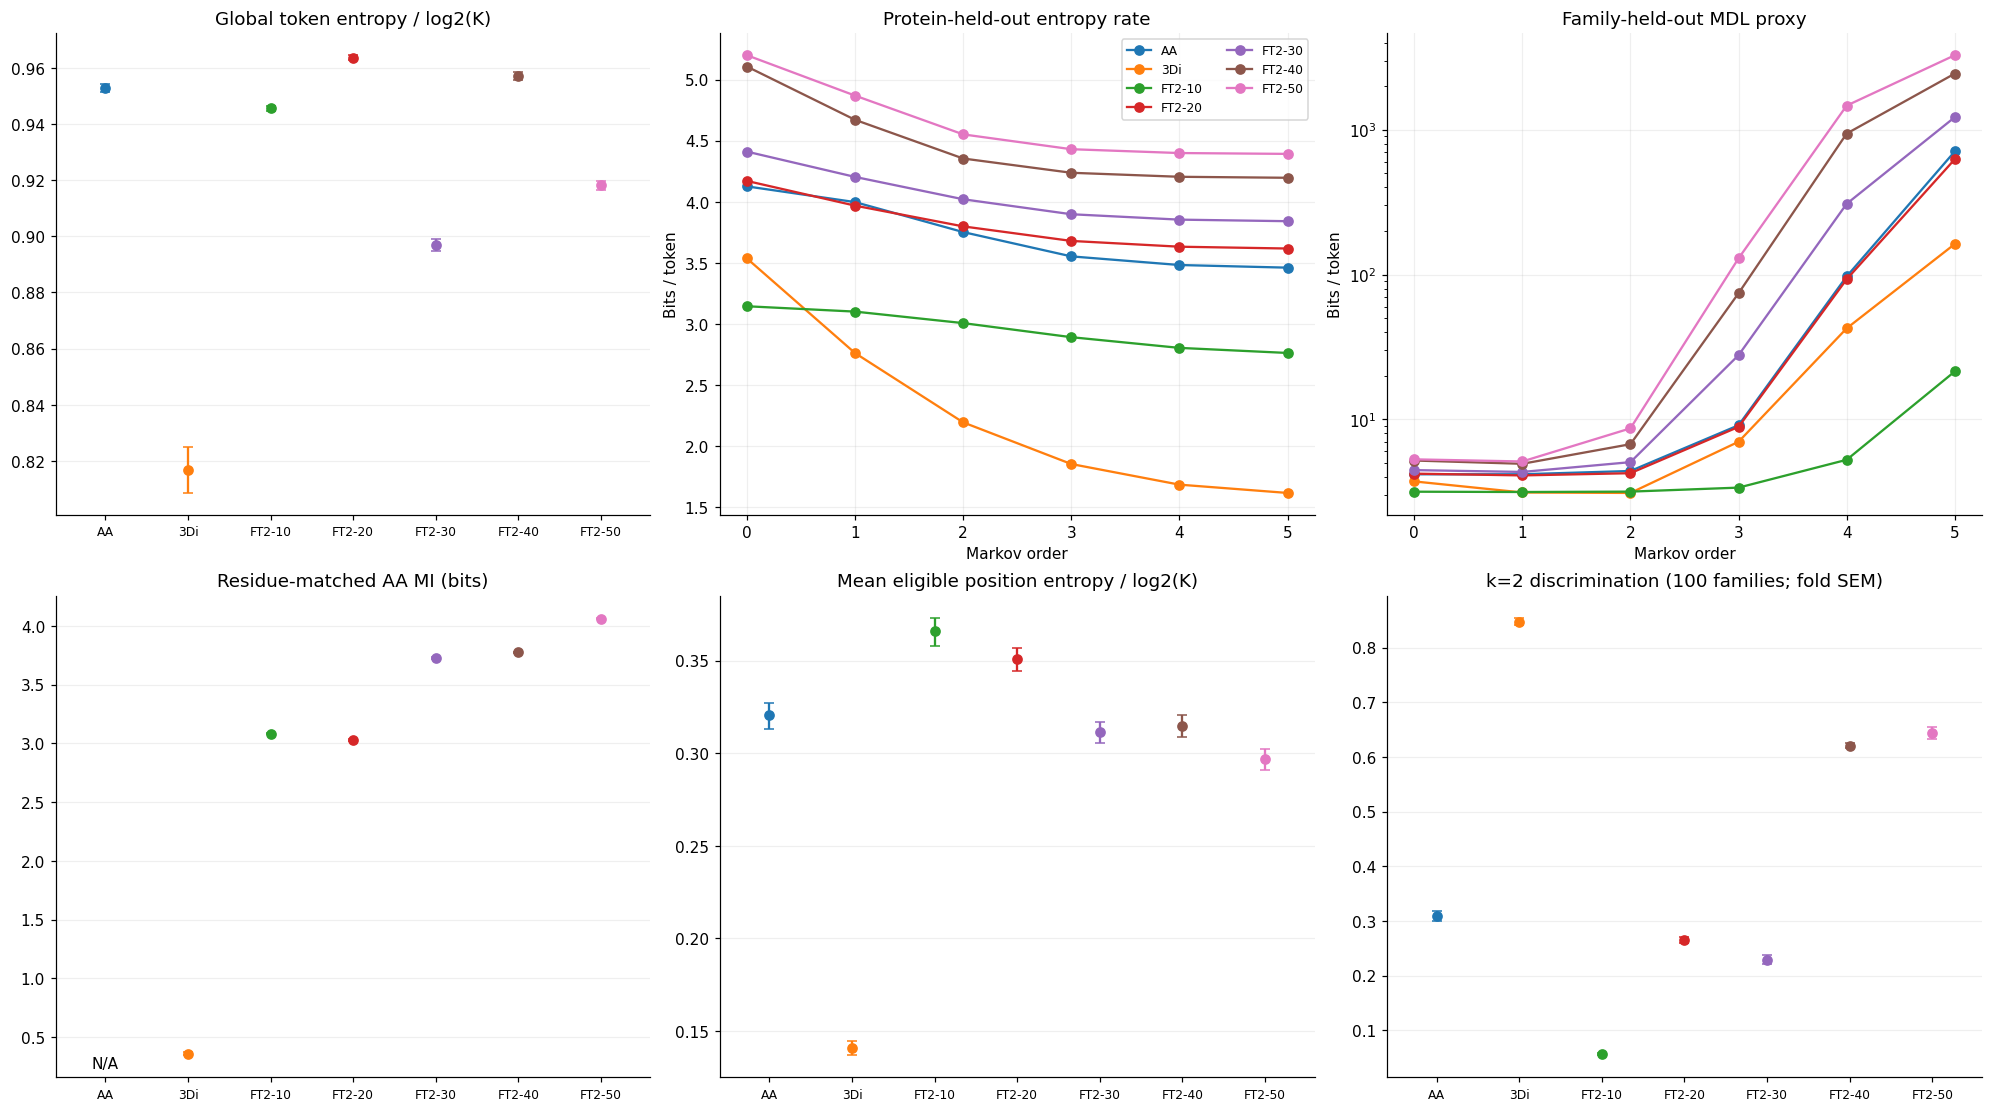

In [3]:
info_parts = {name: [] for name in ['alphabet_usage', 'entropy_rates', 'mdl', 'aa_token_mi',
                                    'position_entropy', 'column_equivalent_mi', 'kmer_discrimination']}
for source, root in GAIN_SOURCES.items():
    directory = root / 'information'
    if json.loads((directory / 'completed.json').read_text()) != json.loads((root / 'provenance.json').read_text()):
        raise ValueError(f'Information completion mismatch: {directory}')
    retained = SOURCE_REPRESENTATIONS[source]
    for name in info_parts:
        if name in ['position_entropy', 'column_equivalent_mi']:
            metric = 'entropy_bits' if name == 'position_entropy' else 'mi_bits'
            partials = []
            for chunk in pd.read_csv(directory / f'{name}.csv', dtype={'family': str},
                                     usecols=['model', 'family', metric], chunksize=100000):
                chunk = chunk[chunk.model.isin(retained)]
                if not np.isfinite(chunk[metric]).all():
                    raise ValueError(f'Nonfinite information metric: {directory}/{name}')
                partials.append(chunk.groupby(['model', 'family'])[metric].agg(['sum', 'count']))
            totals = pd.concat(partials).groupby(level=[0, 1]).sum()
            frame = (totals['sum'] / totals['count']).rename(metric).reset_index()
        else:
            frame = pd.read_csv(directory / f'{name}.csv', dtype={'family': str})
            frame = frame[frame.model.isin(retained)].copy()
        frame = frame.rename(columns={'model': 'representation'})
        if 'family' in frame:
            keys = ['family', 'representation'] + (['order'] if name == 'entropy_rates' else [])
            if frame.duplicated(keys).any() or not set(frame.family) <= family_ids:
                raise ValueError(f'Duplicate/unknown information families: {name}/{source}')
            for representation, group in frame.groupby('representation'):
                if set(group.family) != family_ids:
                    raise ValueError(f'Incomplete information families: {name}/{representation}')
        info_parts[name].append(frame)
info = {name: pd.concat(parts, ignore_index=True) for name, parts in info_parts.items()}
usage = info['alphabet_usage'].copy()
usage['normalized_usage_entropy'] = usage.entropy_bits / np.log2(usage.representation.map(SIZES))
positions = info['position_entropy'].copy()
positions['normalized_position_entropy'] = positions.entropy_bits / np.log2(positions.representation.map(SIZES))
display(usage.groupby('representation').agg(families=('family', 'nunique'),
    entropy_bits=('entropy_bits', 'mean'), effective_states=('effective_states', 'mean')).reindex(REPRESENTATIONS).round(4))
display(info['column_equivalent_mi'].groupby('representation').mi_bits.mean().reindex(REPRESENTATIONS)
        .rename('mean_family_column_equivalent_MI_bits').to_frame())
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
for x, representation in enumerate(REPRESENTATIONS):
    color = COLORS[representation]
    for ax, table, column in [(axes[0, 0], usage, 'normalized_usage_entropy'),
                              (axes[1, 1], positions, 'normalized_position_entropy')]:
        point(ax, x, table.loc[table.representation == representation, column], color)
    for ax, name, column in [(axes[0, 1], 'entropy_rates', 'entropy_rate_bits'),
                             (axes[0, 2], 'mdl', 'mdl_proxy_bits_per_token')]:
        means = info[name].query('representation == @representation').groupby('order')[column].mean()
        ax.plot(means.index, means, marker='o', color=color, label=representation.replace('_', '-'))
    mi = info['aa_token_mi'].query('representation == @representation')
    if mi.empty:
        axes[1, 0].text(x, .02, 'N/A', ha='center', transform=axes[1, 0].get_xaxis_transform())
    else:
        point(axes[1, 0], x, mi.mi1_bits, color)
    discrimination = info['kmer_discrimination'].query('representation == @representation and k == "k=2" and weighted == False')
    if len(discrimination) != 1:
        raise ValueError(f'Expected one k=2 discrimination score: {representation}')
    row = discrimination.iloc[0]
    axes[1, 2].errorbar(x, row.accuracy_mean, yerr=row.accuracy_sem, fmt='o', color=color, capsize=3)
for ax in [axes[0, 0], *axes[1]]:
    alphabet_axis(ax)
for ax in axes[0, 1:]:
    ax.set_xlabel('Markov order')
    ax.set_ylabel('Bits / token')
    ax.grid(alpha=.2)
for ax, title in zip(axes.flat, ['Global token entropy / log2(K)', 'Protein-held-out entropy rate',
                                'Family-held-out MDL proxy', 'Residue-matched AA MI (bits)',
                                'Mean eligible position entropy / log2(K)', 'k=2 discrimination (100 families; fold SEM)']):
    ax.set_title(title)
axes[0, 1].legend(fontsize=8, ncol=2)
axes[0, 2].set_yscale('log')
plt.show()

## 3. Phylogenetic gain and same-run AA contrasts

Gain = log L(tree) - log L(IID), in **nats per eligible alignment column**.
The IID baseline uses that representation's background state frequencies.
Positive values favor the fitted tree over that IID baseline; they do not
establish topology accuracy or ancestral accuracy.

Each point first averages eligible columns within a family, then weights
families equally. Right panels subtract the same-run AA family mean before
bootstrapping. Controlled contrasts use matched columns/topology within each
source; native contrasts are family-paired but **not column-paired**.
We deliberately avoid the legacy gain/(tip entropy + epsilon) statistic:
invariant columns can make it enormous. Units and model/alphabet differences
still matter for the unnormalized gain.

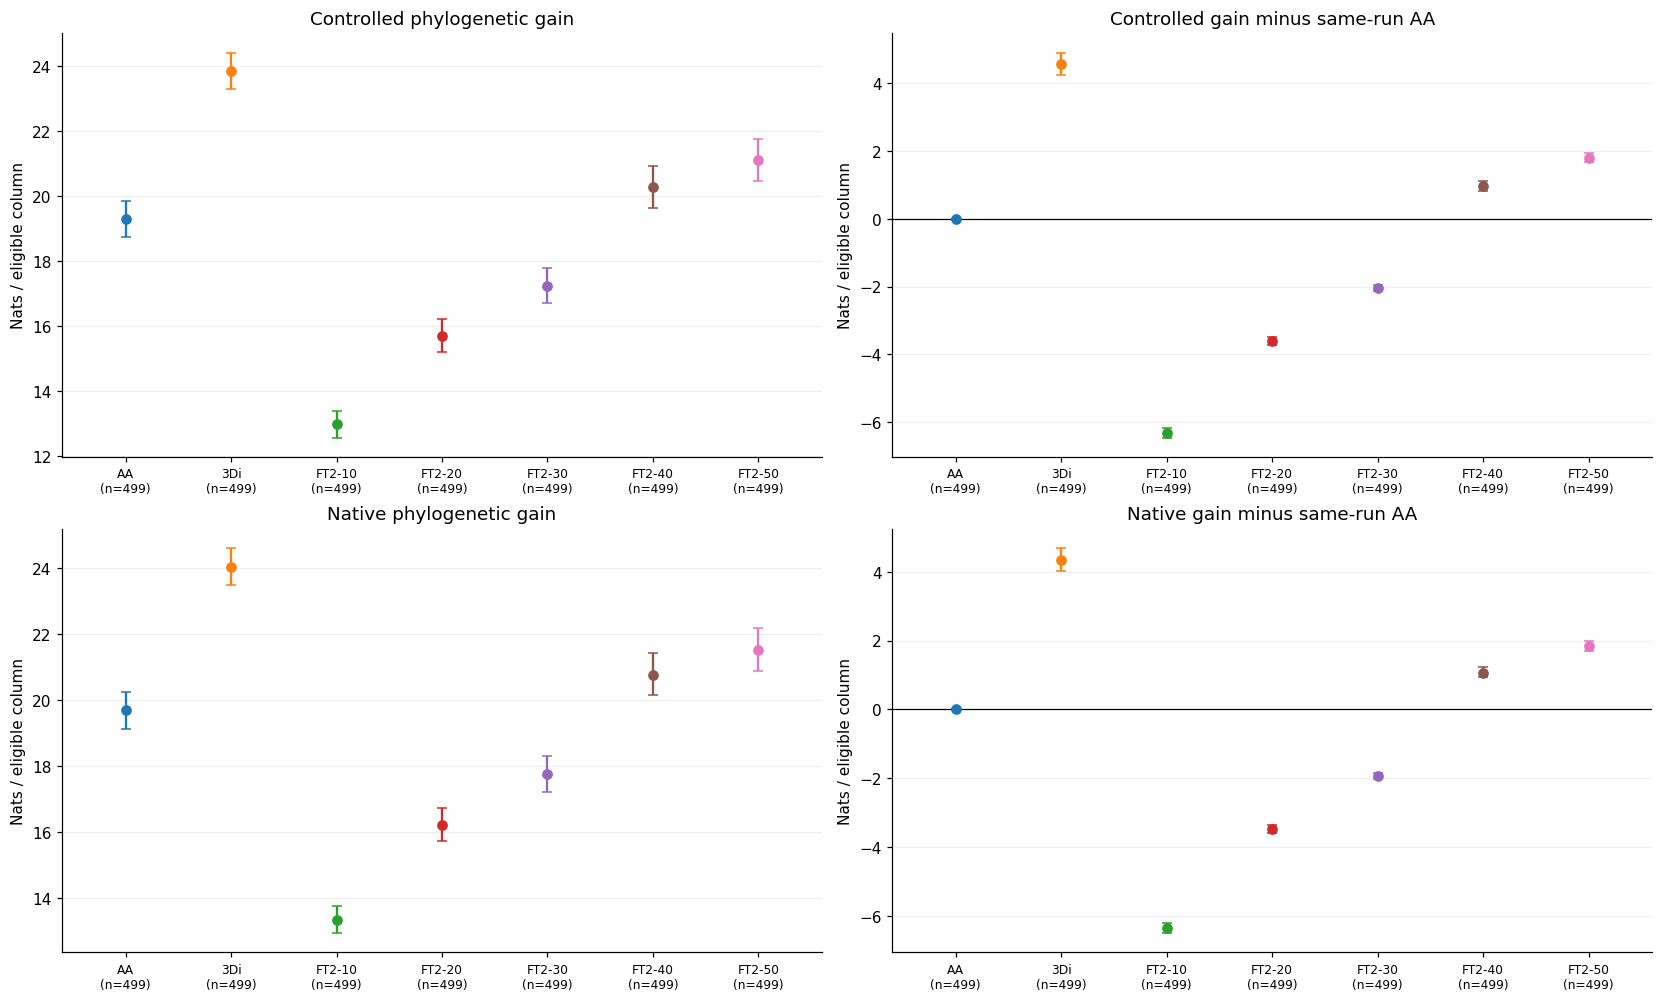

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for row, mode in enumerate(['controlled', 'native']):
    subset = gain.query('mode == @mode')
    deltas = gain_deltas.query('mode == @mode')
    for x, representation in enumerate(REPRESENTATIONS):
        point(axes[row, 0], x, subset.loc[subset.representation == representation, 'phylo_gain_mean'], COLORS[representation])
        point(axes[row, 1], x, deltas.loc[deltas.representation == representation, 'gain_minus_AA'], COLORS[representation])
    for ax in axes[row]:
        alphabet_axis(ax, subset.groupby('representation').family.nunique())
        ax.set_ylabel('Nats / eligible column')
    axes[row, 0].set_title(f'{mode.capitalize()} phylogenetic gain')
    axes[row, 1].set_title(f'{mode.capitalize()} gain minus same-run AA')
    axes[row, 1].axhline(0, color='black', linewidth=.8)
plt.show()

## 4. Native ancestral sharpness and depth

Use the common family intersection across the six available native ASR
representations, excluding legacy tied-MAD-root outputs. FT2-50 is unavailable.
Depth is normalized root-to-node substitution distance in each own tree, not
time or a shared node identity. Synthetic roots have no invented posterior.

Occupancy-passing columns have at least four valid tips and at most 30%
missing tips. Within family/depth bin, average eligible node/sites; then
weight families equally. Shading is a 95% whole-family bootstrap interval.
Maximum probability and adjusted sharpness increase with concentration;
normalized entropy decreases. Concentration is confidence, **not accuracy**.

In [5]:
cohort = json.loads((REPO / 'configs/oma_benchmark_cohort.json').read_text())
family_ids = {row['family'] for row in cohort['families']}
available, problems = inventory(RESULT_ROOTS, family_ids)
coverage = available.groupby('representation').family.nunique().reindex(REPRESENTATIONS, fill_value=0)
display(coverage.rename('completed_families').to_frame().assign(expected_families=len(family_ids)))
if not problems.empty:
    display(problems)
    raise ValueError('Resolve invalid/conflicting artifacts before interpretation.')
from ete3 import Tree
invalid_roots = []
for item in available.itertuples(index=False):
    directory = Path(item.directory)
    roots = directory / 'mad_input.nwk.rooted'
    if not roots.is_file():
        raise ValueError(f'Missing MAD root candidates: {directory}')
    count = sum(bool(line.strip()) for line in roots.read_text().splitlines())
    if count != 1:
        invalid_roots.append({'family': item.family, 'representation': item.representation,
                              'reason': f'{count} MAD roots'})
        continue
    tree = Tree(str(directory / 'rooted.nwk'), format=1)
    if len(tree.get_leaf_names()) != len(set(tree.get_leaf_names())):
        raise ValueError(f'Duplicate taxa in rooted tree: {directory}')
excluded_roots = pd.DataFrame(invalid_roots, columns=['family', 'representation', 'reason'])
if not excluded_roots.empty:
    display(excluded_roots)
    bad_pairs = set(zip(excluded_roots.family, excluded_roots.representation))
    available = available[[pair not in bad_pairs for pair in zip(available.family, available.representation)]]
selected = select_cohort(available, common=COMMON_FAMILIES, max_families=MAX_FAMILIES)
display(selected.groupby('representation').agg(families=('family', 'nunique'), nodes=('n_nodes', 'sum')))
print('Rooting:', selected.rooting.value_counts().to_dict())
print('Valid common families:', selected.family.nunique(), '/ 499; tied-root native runs excluded.')
print('Completion/provenance metadata checked; full output SHA256s are not recomputed during inspection.')

,completed_families,expected_families
representation,,
AA,499,499
3Di,499,499
FT2_10,499,499
FT2_20,499,499
FT2_30,499,499
FT2_40,499,499
FT2_50,0,499


,family,representation,reason
0,1029405,FT2_40,3 MAD roots
1,1058810,FT2_20,2 MAD roots
2,1058812,3Di,3 MAD roots
3,1067221,FT2_20,2 MAD roots
4,1067342,FT2_20,3 MAD roots
5,1067375,AA,2 MAD roots
6,1067442,AA,2 MAD roots
7,1312486,FT2_30,3 MAD roots
8,1332735,FT2_40,2 MAD roots
9,1335742,3Di,2 MAD roots


,families,nodes
representation,,
3Di,461,6020
AA,461,6020
FT2_10,461,6020
FT2_20,461,6020
FT2_30,461,6020
FT2_40,461,6020


Rooting: {'MAD_inferred': 2766}
Valid common families: 461 / 499; tied-root native runs excluded.
Completion/provenance metadata checked; full output SHA256s are not recomputed during inspection.


In [6]:
# Verify posterior outputs and require identical native gain/ASR inputs before joining.
for item in selected.itertuples(index=False):
    signature = verify_stage(Path(item.directory))
    stage = native_gain_signatures[(item.family, item.representation)]
    if signature['protocol'] != 'own_alignment_own_tree_marginal_uncertainty_v2':
        raise ValueError(f'Unexpected ancestral protocol: {item.directory}')
    inputs = set(signature['inputs'].values())
    required = {stage['alignment_sha256'], stage['tree_sha256'], stage['model_sha256']}
    if not required <= inputs:
        raise ValueError(f'Native gain and ASR did not use the same fitted inputs: {item.directory}')
print(f'Hash-verified {len(selected)} native ancestral stages and matched gain inputs.')

Hash-verified 2766 native ancestral stages and matched gain inputs.


In [7]:
family_bins, eligibility = summarize_depth(selected, bins=DEPTH_BINS)
curves = bootstrap_curves(family_bins, draws=BOOTSTRAP_DRAWS, seed=SEED)
display(eligibility.groupby('representation')[['total_node_sites', 'eligible_node_sites']].sum())
display(curves.query("tip_entropy_group == 'all' and metric == 'max_probability'").pivot(index='depth_midpoint', columns='representation', values='n_families').fillna(0).astype(int))

,total_node_sites,eligible_node_sites
representation,,
3Di,3790235,2554318
AA,3853337,2621315
FT2_10,3795515,2629389
FT2_20,3849389,2629410
FT2_30,3873519,2615161
FT2_40,3789467,2643836


representation,3Di,AA,FT2_10,FT2_20,FT2_30,FT2_40
depth_midpoint,,,,,,
0.05,357,296,408,413,428,401
0.15,397,368,438,435,452,439
0.25,397,410,453,450,453,450
0.35,366,424,428,427,436,415
0.45,284,369,368,327,353,339
0.55,191,295,268,205,246,227
0.65,88,177,160,127,136,116
0.75,47,87,89,42,56,53
0.85,18,23,24,15,14,16


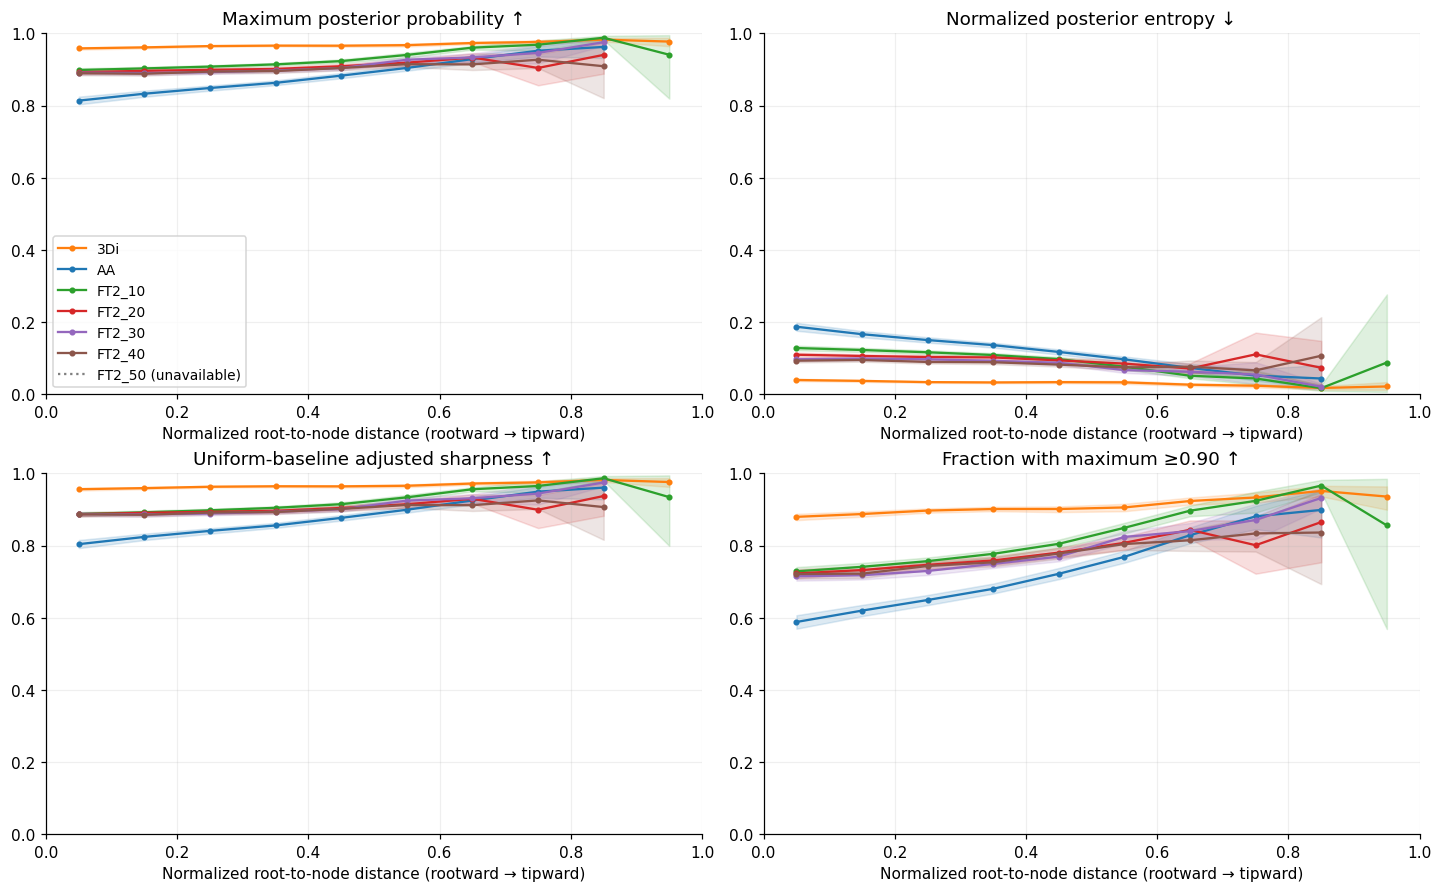

In [8]:
def plot_curve(ax, metric, entropy_group='all'):
    table = curves[(curves.metric == metric) & (curves.tip_entropy_group == entropy_group)]
    for name, group in table.groupby('representation'):
        group = group.sort_values('depth_bin')
        supported = group.n_families >= MIN_FAMILIES_PER_BIN
        x = group.depth_midpoint.to_numpy()
        ax.plot(x, group['mean'].where(supported).to_numpy(), marker='o', markersize=3, color=COLORS[name], label=name)
        ax.fill_between(x, group.lower.where(supported).to_numpy(), group.upper.where(supported).to_numpy(), color=COLORS[name], alpha=.15)
    for name in REPRESENTATIONS:
        if name not in set(table.representation):
            ax.plot([], [], color='gray', linestyle=':', label=name + ' (unavailable)')
    ax.set(xlabel='Normalized root-to-node distance (rootward → tipward)', ylim=(0, 1), xlim=(0, 1))
    ax.grid(alpha=.2)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, metric, title in zip(axes.flat, ['max_probability', 'normalized_entropy', 'sharpness', 'confidence_090'], ['Maximum posterior probability ↑', 'Normalized posterior entropy ↓', 'Uniform-baseline adjusted sharpness ↑', 'Fraction with maximum ≥0.90 ↑']):
    plot_curve(ax, metric)
    ax.set_title(title)
axes[0, 0].legend(fontsize=9)
plt.show()

## 5. Family-matched gain versus ancestral uncertainty

Native gain and native RAxML ASR are joined **one-to-one by family and
representation**, after checking alignment/tree/model hashes. Ancestral family
means below weight depth-bin means by their eligible node/site counts, not by
the number of bins. Gain and ASR have compatible occupancy rules but different
measurement units (columns versus ancestral node/sites); these are family-level
associations, not site-level probability/gain joins.

Each dot is one family. All scatter panels share the same x- and y-axis ranges.
Marginal histograms show family distributions using common bins and density
scales; dashed lines and labels mark each representation's means.
Spearman rho is computed **within each representation**,
avoiding a pooled cross-alphabet correlation. Family size, conservation and
model fit can drive associations; rho is descriptive and not causal.

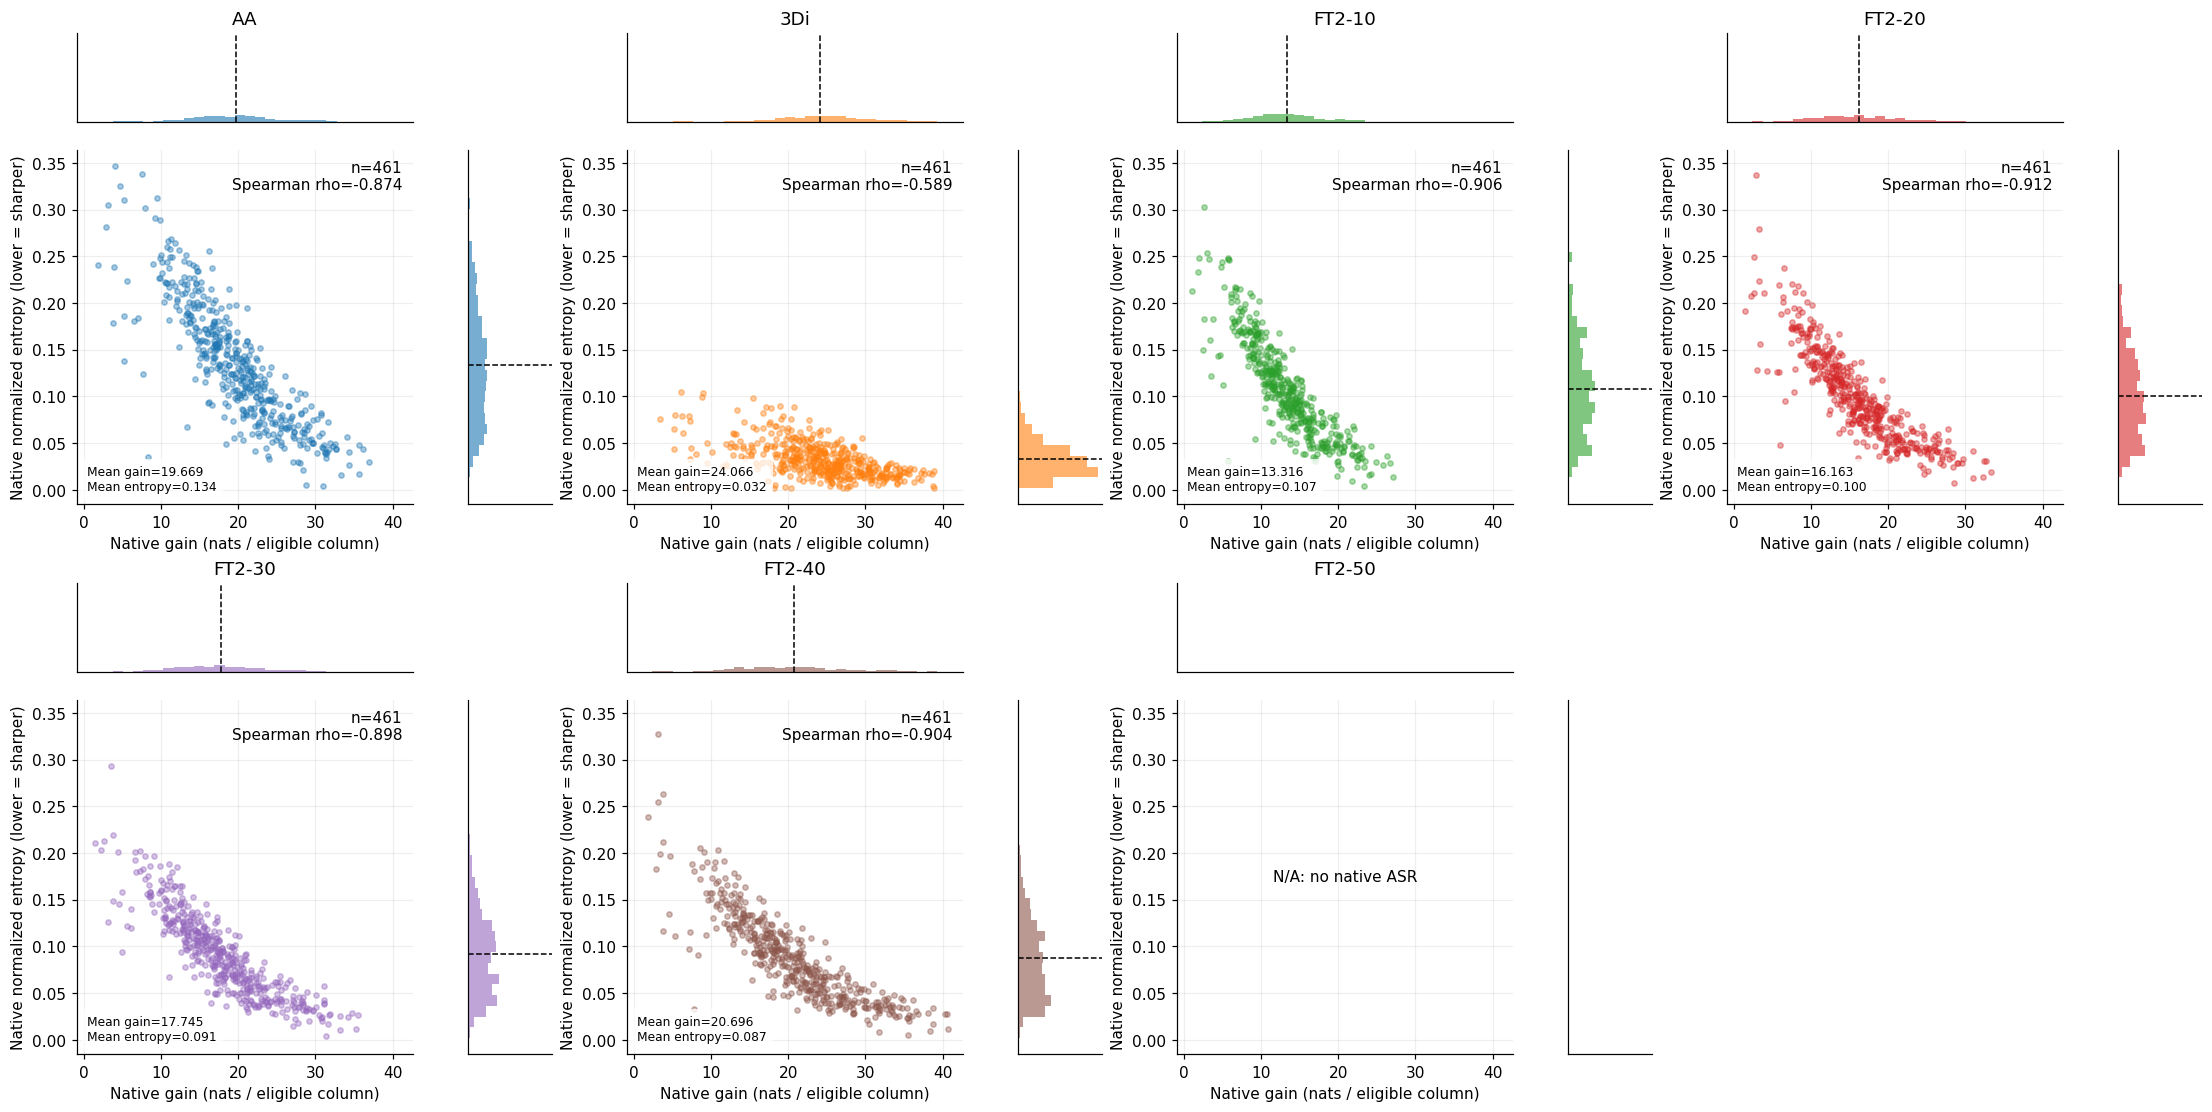

,families,spearman_rho
representation,,
AA,461.0,-0.874174
3Di,461.0,-0.588789
FT2_10,461.0,-0.905714
FT2_20,461.0,-0.912121
FT2_30,461.0,-0.898067
FT2_40,461.0,-0.903863
FT2_50,NaN,NaN


,families,gain_nats_per_column,normalized_entropy,max_probability,normalized_usage_entropy,order_one_entropy_rate_bits,aa_MI_bits
representation,,,,,,,
AA,461.0,19.6692,0.1339,0.8651,0.9530,3.9996,NaN
3Di,461.0,24.0660,0.0324,0.9659,0.8176,2.7659,0.3554
FT2_10,461.0,13.3157,0.1074,0.9148,0.9455,3.1004,3.0802
FT2_20,461.0,16.1633,0.0999,0.9023,0.9635,3.9691,3.0304
FT2_30,461.0,17.7448,0.0913,0.8984,0.8972,4.2047,3.7279
FT2_40,461.0,20.6958,0.0873,0.8970,0.9571,4.6752,3.7749
FT2_50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
all_bins = family_bins[family_bins.tip_entropy_group == 'all'].copy()
for metric in METRICS:
    all_bins[metric] *= all_bins.n_node_sites
native_family = all_bins.groupby(['family', 'representation'])[
    ['n_node_sites', *METRICS]].sum().reset_index()
for metric in METRICS:
    native_family[metric] /= native_family.n_node_sites
if len(native_family) != len(selected):
    raise ValueError('Some selected families have no eligible ancestral node/sites')
joined = gain[gain['mode'] == 'native'].merge(
    native_family, on=['family', 'representation'], how='inner', validate='one_to_one')
if len(joined) != len(native_family):
    raise ValueError('Native gain/sharpness join lost families')
joined = joined.merge(usage[['family', 'representation', 'normalized_usage_entropy']],
    on=['family', 'representation'], validate='one_to_one')
order_one = info['entropy_rates'].query('order == 1')[
    ['family', 'representation', 'entropy_rate_bits']].rename(
        columns={'entropy_rate_bits': 'order_one_entropy_rate_bits'})
joined = joined.merge(order_one, on=['family', 'representation'], validate='one_to_one')
joined = joined.merge(info['aa_token_mi'][['family', 'representation', 'mi1_bits']],
    on=['family', 'representation'], how='left', validate='one_to_one')
if len(joined) != len(native_family):
    raise ValueError('Information join lost gain/sharpness families')
correlation_rows = []
fig = plt.figure(figsize=(20, 10), constrained_layout=True)
panels = fig.add_gridspec(2, 4)
gain_bins = np.histogram_bin_edges(joined.phylo_gain_mean, bins=30)
entropy_bins = np.histogram_bin_edges(joined.normalized_entropy, bins=30)
scatter_axes, gain_axes, entropy_axes = [], [], []
for index, representation in enumerate(REPRESENTATIONS):
    panel = panels[index // 4, index % 4].subgridspec(
        2, 2, width_ratios=[4, 1], height_ratios=[1, 4], hspace=.05, wspace=.05)
    ax = fig.add_subplot(panel[1, 0], sharex=scatter_axes[0] if scatter_axes else None,
                         sharey=scatter_axes[0] if scatter_axes else None)
    gain_ax = fig.add_subplot(panel[0, 0], sharex=ax)
    entropy_ax = fig.add_subplot(panel[1, 1], sharey=ax)
    scatter_axes.append(ax)
    gain_axes.append(gain_ax)
    entropy_axes.append(entropy_ax)
    group = joined[joined.representation == representation]
    gain_ax.set_title(representation.replace('_', '-'))
    if group.empty:
        ax.text(.5, .5, 'N/A: no native ASR', ha='center', va='center', transform=ax.transAxes)
    else:
        rho = group.phylo_gain_mean.corr(group.normalized_entropy, method='spearman')
        if not np.isfinite(rho):
            raise ValueError(f'Undefined gain/entropy correlation: {representation}')
        ax.scatter(group.phylo_gain_mean, group.normalized_entropy, s=12, alpha=.4, color=COLORS[representation])
        mean_gain = group.phylo_gain_mean.mean()
        mean_entropy = group.normalized_entropy.mean()
        gain_ax.hist(group.phylo_gain_mean, bins=gain_bins, density=True, color=COLORS[representation], alpha=.6)
        entropy_ax.hist(group.normalized_entropy, bins=entropy_bins, density=True,
                        orientation='horizontal', color=COLORS[representation], alpha=.6)
        gain_ax.axvline(mean_gain, color='black', linestyle='--', linewidth=1)
        entropy_ax.axhline(mean_entropy, color='black', linestyle='--', linewidth=1)
        ax.text(.03, .03, f'Mean gain={mean_gain:.3f}\nMean entropy={mean_entropy:.3f}',
                ha='left', va='bottom', transform=ax.transAxes, fontsize=8,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .8})
        ax.text(.97, .97, f'n={len(group)}\nSpearman rho={rho:.3f}', ha='right', va='top', transform=ax.transAxes)
        correlation_rows.append({'representation': representation, 'families': len(group), 'spearman_rho': rho})
    ax.tick_params(labelbottom=True, labelleft=True)
    ax.set_xlabel('Native gain (nats / eligible column)')
    ax.set_ylabel('Native normalized entropy (lower = sharper)')
    ax.grid(alpha=.2)
    gain_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    gain_ax.set_yticks([])
    entropy_ax.tick_params(axis='y', left=False, labelleft=False)
    entropy_ax.set_xticks([])
gain_density_max = max(ax.get_ylim()[1] for ax in gain_axes)
entropy_density_max = max(ax.get_xlim()[1] for ax in entropy_axes)
for ax in gain_axes:
    ax.set_ylim(0, gain_density_max)
for ax in entropy_axes:
    ax.set_xlim(0, entropy_density_max)
plt.show()
display(pd.DataFrame(correlation_rows).set_index('representation').reindex(REPRESENTATIONS))
display(joined.groupby('representation').agg(families=('family', 'nunique'),
    gain_nats_per_column=('phylo_gain_mean', 'mean'), normalized_entropy=('normalized_entropy', 'mean'),
    max_probability=('max_probability', 'mean'),
    normalized_usage_entropy=('normalized_usage_entropy', 'mean'),
    order_one_entropy_rate_bits=('order_one_entropy_rate_bits', 'mean'),
    aa_MI_bits=('mi1_bits', 'mean')).reindex(REPRESENTATIONS).round(4))

## 6. Paired ARPIP versus fitted and constant-rate RAxML

This is a separate 499-family cohort per completed representation, **not** the
native common-family subset above. The three methods share native alignments,
trees and topology-matched ancestral nodes within a representation; entropy is
measured on the same ARPIP-present node/sites, without an occupancy filter.
They are not paired node/sites across alphabets.

ARPIP substitution marginals condition on one inferred insertion point and
presence mask, not all indel histories. Gap fractions are deterministic inferred
absence, not calibrated gap probabilities. Fitted RAxML may include invariant
sites and, for AA/3Di, gamma variation. The constant-rate control removes both.
Fixed experimental indel rates limit interpretation.

In [10]:
from scripts.benchmark_common import digest
from scripts.benchmarks.benchmark_cohort import verify_stage

INDEL_ROOT = REPO / 'runs/local_benchmarks/indel_asr_full_conditional_20261108'
indel_signature = verify_stage(INDEL_ROOT)
if digest(REPO / 'configs/oma_benchmark_cohort.json') != indel_signature['cohort_sha256']:
    raise ValueError('Frozen cohort does not match the indel benchmark')
indel_summary = json.loads((INDEL_ROOT / 'summary.json').read_text())
if indel_summary['status'] != 'completed':
    raise ValueError('Indel benchmark is incomplete')
indel = pd.DataFrame(indel_summary['results'])
expected_families = set(indel_signature['families'])
expected_sizes = {f'FT2_{size}' for size in indel_signature['sizes']}
expected_pairs = {(family, size) for family in expected_families for size in expected_sizes}
actual_pairs = set(zip(indel.family, indel.representation))
if (len(indel) != len(expected_pairs) or actual_pairs != expected_pairs
        or expected_families != family_ids or expected_sizes != {'FT2_20', 'FT2_30', 'FT2_40'}):
    raise ValueError('Indel results do not cover the complete frozen cohort and three alphabets')
if ((indel.present_sites <= 0).any()
        or (indel.n_node_sites != indel.present_sites + indel.arpip_gap_sites).any()):
    raise ValueError('Invalid ARPIP presence/gap counts')

indel['alphabet_size'] = indel.representation.str.removeprefix('FT2_').astype(int)
methods = {'ARPIP': 'arpip', 'RAxML fitted': 'raxml', 'RAxML constant': 'raxml_constant'}
for label, column in methods.items():
    indel[label] = indel[f'mean_entropy_{column}_present'] / np.log2(indel.alphabet_size)
if not np.isfinite(indel[list(methods) + ['arpip_gap_fraction']].to_numpy()).all():
    raise ValueError('Nonfinite benchmark entropy or gap values')
if not indel[list(methods) + ['arpip_gap_fraction']].apply(lambda col: col.between(0, 1)).all().all():
    raise ValueError('Benchmark entropy or gap values outside [0, 1]')
display(indel.groupby('representation').agg(
    families=('family', 'nunique'), shared_node_sites=('n_node_sites', 'sum'),
    present_node_sites=('present_sites', 'sum'), mean_gap_fraction=('arpip_gap_fraction', 'mean'),
    **{label: (label, 'mean') for label in methods}).round(4))

,families,shared_node_sites,present_node_sites,mean_gap_fraction,ARPIP,RAxML fitted,RAxML constant
representation,,,,,,,
FT2_20,499,4110869,3103027,0.2163,0.1169,0.1202,0.1169
FT2_30,499,4137244,3122056,0.2171,0.1103,0.1141,0.1102
FT2_40,499,4049047,3086759,0.2099,0.1031,0.1050,0.1031


In [11]:
PROTEIN_ROOT = REPO / 'runs/local_benchmarks/indel_asr_protein_conditional_20261108'
protein_signature = json.loads((PROTEIN_ROOT / 'provenance.json').read_text())
if (protein_signature['protocol'] != 'paired_native_protein_indel_cohort_v1'
        or protein_signature['cohort_sha256'] != indel_signature['cohort_sha256']
        or set(protein_signature['families']) != expected_families
        or set(protein_signature['representations']) != {'AA', '3Di'}):
    raise ValueError('Protein benchmark provenance does not match the frozen cohort')
if (PROTEIN_ROOT / 'completed.json').exists():
    verify_stage(PROTEIN_ROOT)
    protein_snapshot = json.loads((PROTEIN_ROOT / 'summary.json').read_text())
    if protein_snapshot['status'] != 'completed':
        raise ValueError('Protein completion record has incomplete status')
else:
    protein_snapshot = json.loads((PROTEIN_ROOT / 'progress.json').read_text())
    if protein_snapshot['status'] != 'running':
        raise ValueError('Unknown protein progress status')
protein = pd.DataFrame(protein_snapshot['results'])
if protein.empty or protein.duplicated(['family', 'representation']).any():
    raise ValueError('Protein progress is empty or has duplicate comparisons')
if not set(protein.family) <= expected_families or not set(protein.representation) <= {'AA', '3Di'}:
    raise ValueError('Unexpected family or representation in protein progress')
for row in protein.to_dict('records'):
    family, representation = row['family'], row['representation']
    directory = PROTEIN_ROOT / family / representation
    signature = verify_stage(directory)
    if (signature.get('protocol') != 'paired_native_protein_indel_asr_v1_conditional_marginal'
            or signature.get('representation') != representation):
        raise ValueError(f'Unexpected protein comparison provenance: {directory}')
    recorded = json.loads((directory / 'summary.json').read_text())
    if {key: value for key, value in row.items() if key not in ('family', 'representation')} != recorded:
        raise ValueError(f'Protein progress differs from completed summary: {directory}')
paired_families = (set(protein.loc[protein.representation == 'AA', 'family'])
                   & set(protein.loc[protein.representation == '3Di', 'family']))
protein = protein[protein.family.isin(paired_families)].copy()
if len(paired_families) < 2:
    raise ValueError('Need at least two completed AA/3Di family pairs for bootstrap plots')
if protein_snapshot['status'] == 'completed' and len(paired_families) != len(expected_families):
    raise ValueError('Completed protein benchmark does not cover the frozen cohort')
protein['alphabet_size'] = 20
for label, column in methods.items():
    protein[label] = protein[f'mean_entropy_{column}_present'] / np.log2(20)
if ((protein.present_sites <= 0).any()
        or (protein.n_node_sites != protein.present_sites + protein.arpip_gap_sites).any()
        or not np.isfinite(protein[list(methods) + ['arpip_gap_fraction']].to_numpy()).all()
        or not protein[list(methods) + ['arpip_gap_fraction']].apply(lambda col: col.between(0, 1)).all().all()):
    raise ValueError('Invalid protein entropy or presence/gap counts')
paired_indel = pd.concat([indel, protein], ignore_index=True)
print(f"Protein benchmark (recorded status: {protein_snapshot['status']}): {len(paired_families)}/"
      f"{len(expected_families)} families have both AA and 3Di comparisons.")
display(paired_indel.groupby('representation').agg(
    families=('family', 'nunique'), shared_node_sites=('n_node_sites', 'sum'),
    present_node_sites=('present_sites', 'sum'), mean_gap_fraction=('arpip_gap_fraction', 'mean'),
    **{label: (label, 'mean') for label in methods}).round(4))

Protein benchmark (recorded status: completed): 499/499 families have both AA and 3Di comparisons.


,families,shared_node_sites,present_node_sites,mean_gap_fraction,ARPIP,RAxML fitted,RAxML constant
representation,,,,,,,
3Di,499,4047898,3195899,0.1856,0.0377,0.0470,0.0377
AA,499,4116210,3125748,0.2121,0.1422,0.1632,0.1422
FT2_20,499,4110869,3103027,0.2163,0.1169,0.1202,0.1169
FT2_30,499,4137244,3122056,0.2171,0.1103,0.1141,0.1102
FT2_40,499,4049047,3086759,0.2099,0.1031,0.1050,0.1031


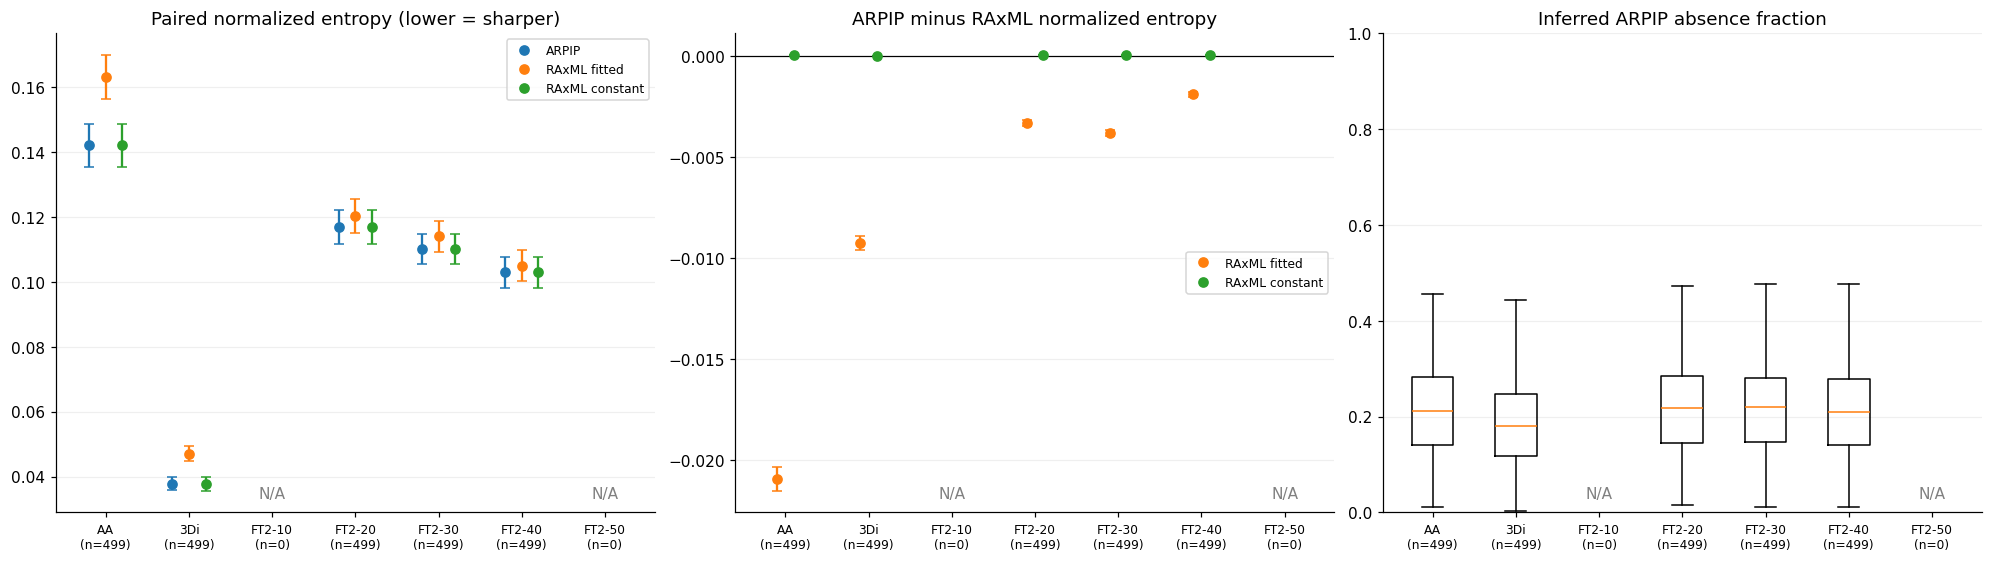

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
counts = paired_indel.groupby('representation').family.nunique()
method_colors = dict(zip(methods, ['tab:blue', 'tab:orange', 'tab:green']))
for x, representation in enumerate(REPRESENTATIONS):
    group = paired_indel[paired_indel.representation == representation].sort_values('family')
    if group.empty:
        for ax in axes:
            ax.text(x, .03, 'N/A', ha='center', transform=ax.get_xaxis_transform(), color='gray')
        continue
    for offset, label in zip([-.2, 0, .2], methods):
        point(axes[0], x, group[label], method_colors[label], offset)
    for offset, label in zip([-.1, .1], ['RAxML fitted', 'RAxML constant']):
        point(axes[1], x, group['ARPIP']-group[label], method_colors[label], offset)
    axes[2].boxplot([group.arpip_gap_fraction.to_numpy()], positions=[x], widths=.5,
                    showfliers=False, manage_ticks=False)
for ax in axes:
    alphabet_axis(ax, counts)
axes[0].set_title('Paired normalized entropy (lower = sharper)')
axes[1].set_title('ARPIP minus RAxML normalized entropy')
axes[1].axhline(0, color='black', linewidth=.8)
axes[2].set_title('Inferred ARPIP absence fraction')
axes[2].set_ylim(0, 1)
for ax, labels in [(axes[0], list(methods)), (axes[1], ['RAxML fitted', 'RAxML constant'])]:
    for label in labels:
        ax.plot([], [], 'o', color=method_colors[label], label=label)
    ax.legend(fontsize=8)
plt.show()

**Reading the paired panels:** normalized entropy is
$-\sum_c p(c)\log_2 p(c)/\log_2 K$, from 0 (one certain character) to 1
(uniform over K characters). The middle panel subtracts RAxML entropy from
ARPIP entropy within each family, so negative means ARPIP is sharper.
Points and bars are equal-family means and 95% family-bootstrap intervals.
The right panel shows per-family inferred absence fractions: median,
interquartile range and 1.5-IQR whiskers, with outliers hidden. These are not
gap confidence estimates. Tick-label n is the paired family count.

## 7. Coverage and interpretation checklist

- **Information/gain**: all seven representations; k-mer discrimination is
  explicitly a smaller classification task.
- **Native depth and gain/sharpness association**: valid common families
  across six representations, excluding ambiguous legacy roots.
- **Paired methods**: AA, 3Di and FT2-20/30/40; FT2-10/50 are N/A.
- **Entropy** is measured in bits; gain uses natural-log likelihoods (nats).
  Normalizing entropy by log2(K) does not erase representation/model effects.
- **Intervals** resample whole families except recorded k-mer fold SEMs.
  Families, not individual ancestral sites, are the replication units.
- **No accuracy claim**: high gain and sharp posteriors can coexist with
  misspecification. Calibration requires known or independently validated
  ancestral truth. Agreement between engines is not ground-truth accuracy.

In [13]:
coverage = pd.DataFrame(index=pd.Index(REPRESENTATIONS, name='representation'))
coverage['information_families'] = usage.groupby('representation').family.nunique()
for mode in ['controlled', 'native']:
    coverage[f'{mode}_gain_families'] = gain[gain['mode'] == mode].groupby('representation').family.nunique()
coverage['native_sharpness_common_families'] = native_family.groupby('representation').family.nunique()
coverage['gain_sharpness_joined_families'] = joined.groupby('representation').family.nunique()
coverage['paired_ARPIP_RAxML_families'] = counts
display(coverage.fillna(0).astype(int))
print('Zero means unavailable, not zero uncertainty or zero gain.')
print('Native exclusions:', len(excluded_roots), 'family/representation outputs; common families:', selected.family.nunique())
print('FT2-50 information/gain uses the explicitly accepted nonconverged matrix.')

,information_families,controlled_gain_families,native_gain_families,native_sharpness_common_families,gain_sharpness_joined_families,paired_ARPIP_RAxML_families
representation,,,,,,
AA,499,499,499,461,461,499
3Di,499,499,499,461,461,499
FT2_10,499,499,499,461,461,0
FT2_20,499,499,499,461,461,499
FT2_30,499,499,499,461,461,499
FT2_40,499,499,499,461,461,499
FT2_50,499,499,499,0,0,0


Zero means unavailable, not zero uncertainty or zero gain.
Native exclusions: 38 family/representation outputs; common families: 461
FT2-50 information/gain uses the explicitly accepted nonconverged matrix.
